# Why Some Students Use AI More Than Others

CS105 Fall'26 Mini-Project

## Topic Overview

*Introduce the topic and give context for the data and research questions.*

## Q1: What data do we have?

*Describe the dataset: source, number of responses, and the features we use.*

## Q2: What would we like to know?

*State the questions we aim to investigate.*

## Data Cleaning

*Columns kept/removed, how missing values were handled, any derived scores.*

## Exploratory Data Analysis

### I. Data Exploration and Visualization

*At least 8 visualizations, at least 6 different types. For each: what we want to learn → code → interpretation.*

In [6]:
#Visual 1 data cleaning
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.mosaicplot import mosaic
from scipy.stats import chi2_contingency, chi2

df = pd.read_csv("../data/uncleaned_data.csv")

# The answers use a curly apostrophe (’). Swap it for a normal one (') so we can type the answers exactly.
df = df.replace("’", "'", regex=True)

# look through the df to find the specific columns in question
procrastinate_col = [c for c in df.columns if "relying on AI more after I procrastinate" in c][0]
no_time_col = [c for c in df.columns if "t have enough time to finish" in c][0]   # "don't have enough time"

# break down the groups like stated in the above markdown cell
procrastinate_groups = {
    "Never": "Never/Rarely",
    "Rarely": "Never/Rarely",
    "Sometimes": "Sometimes",
    "Often": "Often/Always",
    "Always": "Often/Always",
}
no_time_groups = {
    "Trying on my own": "No AI",
    "Seek help from a classmate or TA": "No AI",
    "Leave the problem as incomplete": "No AI",
    "Ask AI for a hint or explanation": "AI hint",
    "Ask AI for the complete solution": "AI full solution",
}

# One row per student with their two grouped answers. Drop students who skipped either question.
data = pd.DataFrame({
    "procrastinate": df[procrastinate_col].map(procrastinate_groups),
    "no_time": df[no_time_col].map(no_time_groups),
}).dropna()

# row and col ordering
col_order = ["Never/Rarely", "Sometimes", "Often/Always"]
tile_order = ["No AI", "AI hint", "AI full solution"]

# create the table that shows the counts and percentages of students
table = pd.crosstab(data["procrastinate"], data["no_time"]).loc[col_order, tile_order]
percent = (table.div(table.sum(axis=1), axis=0) * 100).round(0)



Because some questions had answer choices that were too small on their own, we decided to combine them.

- [CU] "I find myself relying on AI more after I procrastinate" had 5 options (Never | Rarely | Sometimes | Often | Always). We combined "Never" with "Rarely" and "Often" with "Always," and left "Sometimes" as is.

- [BU] "When you don't have enough time to finish your assignment before the deadline" also had 5 options (Try on my own | Ask a classmate or TA | Ask AI for a hint | Ask AI for the complete solution | Leave it incomplete). We combined "Try on my own," "Ask a classmate or TA," and "Leave it incomplete" into one "No AI" group, and left "Ask AI for a hint" and "Ask AI for the complete solution" as they are.

In [7]:
#Visual 2 data cleaning
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/uncleaned_data.csv")

# answers use a curly apostrophe (’), swap it for a normal one (')
df = df.replace("’", "'", regex=True)

# look through the df to find the 8 "how often do you use AI for..." columns
ai_cols = [c for c in df.columns if c.startswith("How often do you use AI for the following:")]

# look through the df to find the 3 reason columns
learn_col = [c for c in df.columns if "learn the material myself" in c][0]
trust_col = [c for c in df.columns if "trust its answers" in c][0]   # "don't trust its answers"
rules_col = [c for c in df.columns if "class rules" in c][0]

# turn each ai use answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {
    "I don't use AI for this": 0,
    "I use it rarely": 1,
    "I use it sometimes": 2,
    "I use it very often": 3,
}
numbers = pd.DataFrame()
for col in ai_cols:
    numbers[col] = df[col].map(to_number)

# break down the groups like stated in the above markdown cell
reason_groups = {
    "Not at all": "Not at all / A little",
    "A little": "Not at all / A little",
    "Somewhat": "Somewhat",
    "A lot": "A lot",
}

# One row per student with their reliance score (average of the 8 numbers, NaNs skipped) and their three grouped answers.
# NaNs are kept here, seaborn drops them for each panel on its own.
data = pd.DataFrame({
    "reliance_score": numbers.mean(axis=1),
    "learn_myself": df[learn_col].map(reason_groups),
    "no_trust": df[trust_col].map(reason_groups),
    "class_rules": df[rules_col].map(reason_groups),
})

To compare students we needed one number for how much each student uses AI (AI-reliance score).

- [CA]–[CH] "How often do you use AI for the following" asked about 8 tasks, each with 4 options (I don't use AI for this | I use it rarely | I use it sometimes | I use it very often).  
Each becomes a value 0–3 and averaged them, so each student gets one **AI-reliance score** from 0 (never) to 3 (very often). Blanks and "Prefer not to answer" were skipped.

We then focused on the questions that put these students into the different groups that we will be observing.

- [DE] "I want to learn the material myself," [DG] "I don't trust its answers," and [DH] "My class rules don't allow it".  
Each had 4 options (Not at all | A little | Somewhat | A lot).  
"Not at all" and "A little" were small groups so they got combined. "Somewhat" and "A lot" were left as is.

In [8]:
#Visual 3 data cleaning
import pandas as pd

# Load the original dataset
df = pd.read_csv("../data/uncleaned_data.csv")

# Keep the original dataset unchanged
df_raw = df.copy()

# Create analysis dataframe
df_sankeyAnalysis = pd.DataFrame()

df_sankeyAnalysis["ai_days"] = pd.to_numeric(df[next(col for col in df.columns if "on how many days did you use AI tools for schoolwork" in col)],errors="coerce")

df_sankeyAnalysis["ai_minutes"] = pd.to_numeric(df[next(col for col in df.columns if "Total minutes:" in col)],errors="coerce")

df_sankeyAnalysis["main_reason"] = df[next(col for col in df.columns
if "main reason for using AI" in col)]

df_sankeyAnalysis["reliance_after_procrastinating"] = df[next(col for col in df.columns
if "I find myself relying on AI more after I procrastinate" in col)]

df_sankeyAnalysis["homework_timing"] = df[next(col for col in df.columns
if "How far in advance do you typically begin working" in col
and "[Homework]" in col)]

df_sankeyAnalysis["coursework_stress"] = pd.to_numeric(df[next(col for col in df.columns
if "[Stress about coursework]" in col)],errors="coerce")

# Clean text columns
text_columns = ["main_reason","reliance_after_procrastinating","homework_timing"]

for col in text_columns:
    df_sankeyAnalysis[col] = df_sankeyAnalysis[col].str.strip()



## ADD DATA CLEANING QUICK EXPLANATION

In [9]:
#Visual 4 data cleaning
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../data/uncleaned_data.csv")
# create crosstable that limit x-axis as "i don't use AI for this, i use it rarelly, etc"
# y-axis as types of questions: "reviewing lecture slides, doing homework for STEM related subjects, etc"
study_df = survey_df.loc[:, "How often do you use AI for the following:\r\n [Reviewing Lecture slides]":"How often do you use AI for the following:\r\n [Asking for definitions]"]
study_df["How often do you use AI for the following:\r\n [Reviewing Lecture slides]"].value_counts()

# Count responses for each study activity
lecture = study_df.iloc[:, 0].value_counts()
coding = study_df.iloc[:, 1].value_counts()
stem = study_df.iloc[:, 2].value_counts()
writing = study_df.iloc[:, 3].value_counts()
calculation = study_df.iloc[:, 4].value_counts()
written_review = study_df.iloc[:, 5].value_counts()
questions = study_df.iloc[:, 6].value_counts()
definitions = study_df.iloc[:, 7].value_counts()



# Combine response counts into one DataFrame
cross_survey = pd.DataFrame({
    "Reviewing Lecture Slides": lecture,
    "Coding Assignments": coding,
    "STEM Homework": stem,
    "Writing Assignments": writing,
    "Calculation Mistakes": calculation,
    "Written Mistakes": written_review,
    "Asking Questions": questions,
    "Asking Definitions": definitions
}).T.fillna(0)

# Reorder the response categories
response_order = ["I use it very often", "I use it sometimes", "I use it rarely", "I don’t use AI for this", "Prefer not to answer"]

cross_survey = cross_survey.reindex(columns=response_order, fill_value=0)

# Calculate percentages
percentage_survey = (cross_survey.div(cross_survey.sum(axis=1), axis=0) * 100)


For the heatmap, we first loaded the original uncleaned_data.csv dataset using pandas. We selected only the eight survey questions related to how frequently students use AI for different study activities, such as reviewing lecture slides, completing homework, reviewing mistakes, and asking questions.

Next, we used value_counts() to count how many students selected each response for every study activity. We then combined these counts into a new DataFrame using pd.DataFrame() and transposed it so that each row represented a study activity and each column represented an AI usage frequency.

We used fillna(0) to replace missing response counts with zero and reindex() to arrange the five frequency categories in a consistent order, from "I use it very often" to "Prefer not to answer" so it follows our original google form. Then we divided each response count by the total number of responses for that activity and multiplied by 100 to convert the counts into percentages.

This preparation allowed us to compare AI usage frequencies across all eight study activities using a heatmap.

Add on to correlation test:
For the correlation test, we selected two study activities from the heatmap dataset: asking questions and reviewing calculation mistakes. We converted the frequency responses into numerical values from 0 to 3, where 0 represents not using AI and 3 represents using AI very often.

We then combined the two variables into a new DataFrame and used dropna() to remove students with missing or non-frequency responses for either activity. This produced 83 valid paired responses for the Spearman correlation analysis.

In [10]:
#Visual 5 data cleaning
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("../data/uncleaned_data.csv")

# Clean up the data by selecting the three homework strategy questions
homework_df = survey_df.loc[:, "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you have more than enough time to finish your assignment before the deadline]" : "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you don’t have enough time to finish your assignment before the deadline]"]

# Count the responses for each deadline situation
more_time = homework_df.iloc[:, 0].value_counts()
just_enough = homework_df.iloc[:, 1].value_counts()
not_enough = homework_df.iloc[:, 2].value_counts()

# Combine the counts into one DataFrame
cross_homework = pd.DataFrame({
    "More than enough time": more_time,
    "Just enough time": just_enough,
    "Not enough time": not_enough
}).T

# Replace missing response with 0
cross_homework = cross_homework.fillna(0)

# Set the order of homework strategies
strategy_order = [
    "Trying on my own",
    "Seek help from a classmate or TA",
    "Ask AI for a hint or explanation",
    "Ask AI for the complete solution",
    "Leave the problem as incomplete"
]

# Reorder the columns
cross_homework = cross_homework.reindex(columns=strategy_order, fill_value=0)


# Calculate the percentage of each homework strategy for each deadline situation
# Divide each count by the total responses in its row
percentage_homework = cross_homework.div(cross_homework.sum(axis=1), axis=0) * 100

For the stacked bar chart, we loaded the original uncleaned_data.csv dataset and selected only the three survey questions about students' preferred homework strategies under different deadline conditions: more than enough time, just enough time, and not enough time.

We used value_counts() to count the responses for each deadline situation and combined the counts into one DataFrame. Each row represented a different deadline condition, while each column represented a homework strategy, such as trying independently, asking a classmate or TA, asking AI for hints or explanations, asking AI for a complete solution, or leaving the problem incomplete.

Next, we used fillna(0) to replace missing response counts with zero and reindex() to arrange the homework strategies in a consistent order. We then divided each response count by the total responses for that deadline condition and multiplied by 100 to calculate the percentages.

This preparation ensured that each deadline condition totaled 100%, allowing us to compare the distribution of homework strategies using a 100% stacked bar chart.

In [11]:
#Visual 6 data cleaning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("survey.csv")


def find_col(*fragments):
    """Return the one column whose name contains every fragment."""
    matches = [c for c in survey_df.columns if all(f in c for f in fragments)]
    assert len(matches) == 1, f"{fragments} matched {len(matches)} columns"
    return matches[0]


freq5 = ["Never", "Rarely", "Sometimes", "Often", "Always"]

axes_spec = [
    ("Relies on AI More\nAfter Procrastinating",
     find_col("I find myself relying on AI more after I procrastinate"),
     freq5),
    ("Starts Homework\nEarly",
     find_col("How far in advance", "[Homework]"),
     ["Same day", "1 - 2 Days Before", "3 - 6 Days Before", "1 Week Before"]),
    ("Willing to Accept\nAI Assistants",
     find_col("How willing are you to accept", "AI Assistants (ChatGPT, Claude)"),
     [1, 2, 3, 4, 5]),
    ("AI Reduces\nCoursework Stress",
     find_col("AI has helped me feel less stressed"),
     ["Strong disagree", "Disagree", "Neutral", "Agree", "Strong agree"]),
    ("'Feels Like Cheating'\nKeeps Me From AI",
     find_col("keep you from using AI", "I feel like I am cheating"),
     ["Not at all", "A little", "Somewhat", "A lot"]),
]

tick_text = {
    "Starts Homework\nEarly": ["Same day", "1-2 days", "3-6 days", "1 week"],
    "Willing to Accept\nAI Assistants": ["Very\nunwilling", "Somewhat\nunwilling", "Neutral",
                                          "Somewhat\nwilling", "Very\nwilling"],
    "AI Reduces\nCoursework Stress": ["Strongly\ndisagree", "Disagree", "Neutral", "Agree",
                                      "Strongly\nagree"],
}

minutes_col = find_col("In the past 7 days, approximately how many minutes")
ai_col = "Minutes of\nAI Used"

df = pd.DataFrame({ai_col: pd.to_numeric(survey_df[minutes_col], errors="coerce")})

axis_names = []
for title, col, labels in axes_spec:
    levels = {lab: i for i, lab in enumerate(labels)}
    raw = survey_df[col]
    if isinstance(labels[0], int):                      # numeric 1-5 questions
        raw = pd.to_numeric(raw, errors="coerce")
    elif raw.dtype == object or str(raw.dtype).startswith("str"):
        raw = raw.astype(str).str.strip()
    df[title] = raw.map(levels) / (len(labels) - 1)
    axis_names.append(title)

df = df.dropna()

ai_cutoff = 400
n_before = len(df)
df = df[df[ai_col] <= ai_cutoff]
n_removed = n_before - len(df)

df = df.sort_values(ai_col)

ai_ticks = [0, 100, 200, 300, 400]
scaled_df = df.copy()
scaled_df[ai_col] = df[ai_col] / ai_cutoff

columns = [ai_col] + axis_names
x = np.arange(len(columns))

bins = [-1, 30, 120, ai_cutoff]
bin_labels = ["0-30 min", "31-120 min", "121-400 min"]
bin_colors = ["#6baed6", "#2ca25f", "#e6550d"]   # light blue, green, orange
group = pd.cut(df[ai_col], bins=bins, labels=bin_labels)
color_map = dict(zip(bin_labels, bin_colors))


## ADD DATA CLEANING QUICK EXPLANATION

In [12]:
#Visual 7 data cleaning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

survey_df = pd.read_csv("survey.csv")


def find_col(*fragments):
    """Return the one column whose name contains every fragment."""
    matches = [c for c in survey_df.columns if all(f in c for f in fragments)]
    assert len(matches) == 1, f"{fragments} matched {len(matches)} columns"
    return matches[0]


# Columns
minutes_col = find_col("In the past 7 days, approximately how many minutes")
reliance_col = find_col("I find myself relying on AI more after I procrastinate")

levels = ["Never", "Rarely", "Sometimes", "Often", "Always"]

df = pd.DataFrame({
    "minutes": pd.to_numeric(survey_df[minutes_col], errors="coerce"),
    "reliance": survey_df[reliance_col].astype(str).str.strip(),
})
df = df[df["reliance"].isin(levels)].dropna()      # drops blanks and double-checked answers


ai_cutoff = 400
n_before = len(df)
df = df[df["minutes"] <= ai_cutoff]
n_removed = n_before - len(df)

## ADD DATA CLEANING QUICK EXPLANATION

In [13]:
#Visual 8 data cleaning
from pathlib import Path
import hashlib
import pandas as pd

# Locate the repository whether launched from this folder or the repository root.
repo_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data' / "uncleaned_data.xlsx").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Could not locate data/uncleaned_data.xlsx in the repository.')
source_path = repo_root / 'data' / "uncleaned_data.xlsx"
output_dir = repo_root / 'working_folders' / 'slian088'
data = pd.read_excel(source_path, sheet_name='Form Responses 1')
print(f'Source: {source_path.relative_to(repo_root)}')
print(f'Responses: {len(data)}; columns: {data.shape[1]}')
print('Workbook SHA-256:', hashlib.sha256(source_path.read_bytes()).hexdigest())

factors = {
    'learn_myself': ('DE', 'I want to learn the material myself'),
    'future_independence': ('DF', 'I need to be able to do it without AI later'),
    'distrust_answers': ('DG', 'I don’t trust its answers'),
    'class_rules': ('DH', "My class rules don't allow it"),
    'feels_like_cheating': ('DI', 'I feel like I am cheating'),
    'lack_of_ai_skills': ('DJ', "I don't know how to use it well"),
}
selected = {}
for short_name, (excel_col, wording) in factors.items():
    matches = [c for c in data.columns
               if c.startswith('When you are working on a homework assignment,')
               and c.strip().endswith(f'[{wording}]')]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one column for {short_name}: {matches}')
    selected[matches[0]] = short_name

raw_factors = data[list(selected)].rename(columns=selected).copy()
raw_factors.index = pd.RangeIndex(2, len(data) + 2, name='source_excel_row')
variable_dictionary = pd.DataFrame([
    {'variable': name, 'original_excel_column': col, 'factor': wording}
    for name, (col, wording) in factors.items()
])
print(variable_dictionary.to_string(index=False))
print('\nFirst five responses (original text):')
print(raw_factors.head().to_string())

score_map = {'Not at all': 0, 'A little': 1, 'Somewhat': 2, 'A lot': 3}
text_factors = raw_factors.apply(lambda col: col.astype('string').str.strip())
text_factors = text_factors.replace('', pd.NA)
unexpected = {
    col: sorted(set(text_factors[col].dropna()) - set(score_map))
    for col in text_factors
}
unexpected = {col: values for col, values in unexpected.items() if values}
if unexpected:
    raise ValueError(f'Unrecognized survey answers: {unexpected}')
clean_factors = text_factors.apply(lambda col: col.map(score_map)).astype('Int64')

missingness = pd.DataFrame({
    'valid_n': clean_factors.count(),
    'missing_n': clean_factors.isna().sum(),
})
print(missingness.to_string())
print(f'\nResponses with all six factors answered: {len(clean_factors.dropna())}')
print(f'Responses with no factors answered: {clean_factors.isna().all(axis=1).sum()}')
print('\nFirst five encoded responses (NA means missing):')
print(clean_factors.head().to_string())

valid_n = clean_factors.count()
high_count = clean_factors.ge(2).sum()
summary = pd.DataFrame({
    'factor': [factors[name][1] for name in clean_factors.columns],
    'valid_n': valid_n,
    'missing_n': clean_factors.isna().sum(),
    'mean_score': clean_factors.mean(),
    'median_score': clean_factors.median(),
    'somewhat_or_a_lot_n': high_count,
    'somewhat_or_a_lot_pct': high_count.div(valid_n.replace(0, float('nan'))).mul(100),
})
summary.index.name = 'variable'
summary = summary.sort_values('mean_score', ascending=False)
print(summary.to_string(index=False, float_format=lambda x: f'{x:.2f}'))

counts = pd.DataFrame({
    col: text_factors[col].value_counts().reindex(list(score_map), fill_value=0)
    for col in text_factors
}).T
counts.index.name = 'variable'
percentages = counts.div(valid_n.replace(0, float('nan')), axis=0).mul(100)
print('\nFull response counts:')
print(counts.to_string())
print('\nPercentages among valid answers:')
print(percentages.round(2).to_string())



Source: data\uncleaned_data.xlsx
Responses: 93; columns: 175
Workbook SHA-256: 278beaf658088440762c000a3b362a01e9a7d88120c711e122c3e135240831c0
           variable original_excel_column                                      factor
       learn_myself                    DE         I want to learn the material myself
future_independence                    DF I need to be able to do it without AI later
   distrust_answers                    DG                   I don’t trust its answers
        class_rules                    DH               My class rules don't allow it
feels_like_cheating                    DI                   I feel like I am cheating
  lack_of_ai_skills                    DJ             I don't know how to use it well

First five responses (original text):
                 learn_myself future_independence distrust_answers class_rules feels_like_cheating lack_of_ai_skills
source_excel_row                                                                                  

## Data cleaning summary

- Keep the six homework-deterrent questions and class standing. Trim spaces and keep blanks as missing.
- Code Not at all = 0, A little = 1, Somewhat = 2, and A lot = 3. Flag unexpected answers.
- For the radar chart, keep Freshman–Senior and use valid answers per item. Exclude the one concurrent response from this chart.
- For paired tests, require all four score items. Average independent learning and future independence for the learning score; average distrust and difficulty using AI for the trust/skill score.
- For the chi-squared test, require both class-rule and cheating answers. Group scores 0–1 as Lower and 2–3 as Higher.

#### Visualization 1: <title>

**What we want to learn:**

# Question

## Idea



**Interpretation:**

#### Visualization 2: <title>

**What we want to learn:**

# What Do Students Use AI For Most?

## Idea

We compared how often students use AI across seven study activities, from reviewing lecture slides to completing STEM homework and writing assignments. We expect students to use AI most for understanding, like asking questions, looking up definitions, and reviewing their mistakes, and less for completing assignments directly.

**Interpretation:**

#### Visualization 3: <title>

**What we want to learn:**

# Does Deadline Pressure Change How Students Get Unstuck?

## Idea

We compared what students do after being stuck on a homework problem for 15 minutes when they have more than enough, just enough, or not enough time before the deadline. We expect that as the deadline gets closer, students turn to AI for hints or complete solutions instead of working through the problem on their own.

**Interpretation:**

#### Visualization 4: <title>

**What we want to learn:**

# Question: What Do Students Use AI For Most?




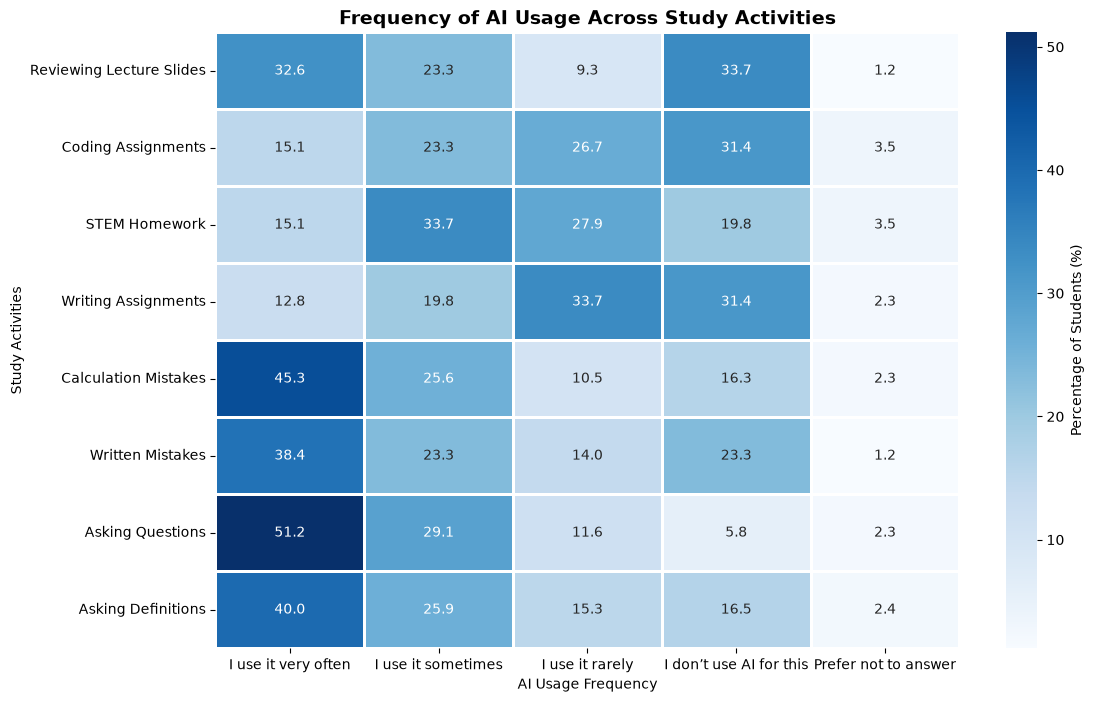

In [14]:

# Create a heatmap
# Set figure size for better readability
plt.figure(figsize=(12, 8))

# cmap='Blues': Darker blue represents a higher percentage
# annot=True: Displays the percentages in each cell
# fmt='.1f': Shows percentages with 1 decimal place
# linewidths=1: Adds spacing between cells
sns.heatmap(percentage_survey, cmap='Blues', annot=True, fmt='.1f',
            linewidths=1, cbar_kws={'label': 'Percentage of Students (%)'})

# Add title and labels
plt.title('Frequency of AI Usage Across Study Activities', fontsize=14, fontweight='bold')
plt.xlabel('AI Usage Frequency')
plt.ylabel('Study Activities')
plt.show()



**Interpretation:**

Survey Question:
How often do you use AI in the given examples to study?

What we suspect:
We think students are more likely to use AI frequently for asking questions, finding definitions, and reviewing mistakes in their work than for completing coding, STEM homework, or writing-based assignments.

Our analysis:
We used responses from eight survey questions about how frequently students use AI for different study activities. Seven activities contain 86 responses each, while asking for definitions contains 85 responses.

We compared the frequency of AI use across these eight study activities. We grouped responses into Very Often, Sometimes, Rarely, Don't Use AI, and Prefer Not to Answer. We then calculated the percentage of students selecting each response and displayed the results using a heatmap.
Findings:
- 80.3% of students use AI very often or sometimes for asking questions or clarifying concepts.
- 70.9% use AI very often or sometimes for reviewing calculation mistakes.
- 65.9% use AI very often or sometimes for asking for definitions.
- 48.8% use AI very often or sometimes for STEM homework.
- 38.4% use AI very often or sometimes for completing coding assignments.
- 32.6% use AI very often or sometimes for writing assignments.

Conclusion:
Students use AI more frequently for understanding concepts and reviewing mistakes than for completing assignments directly. Asking questions and reviewing calculation mistakes are among the most common uses of AI. The results support our hypothesis.

# Question: Deadline Pressure and AI Use

#### Visualization 5: <title>

**What we want to learn:**

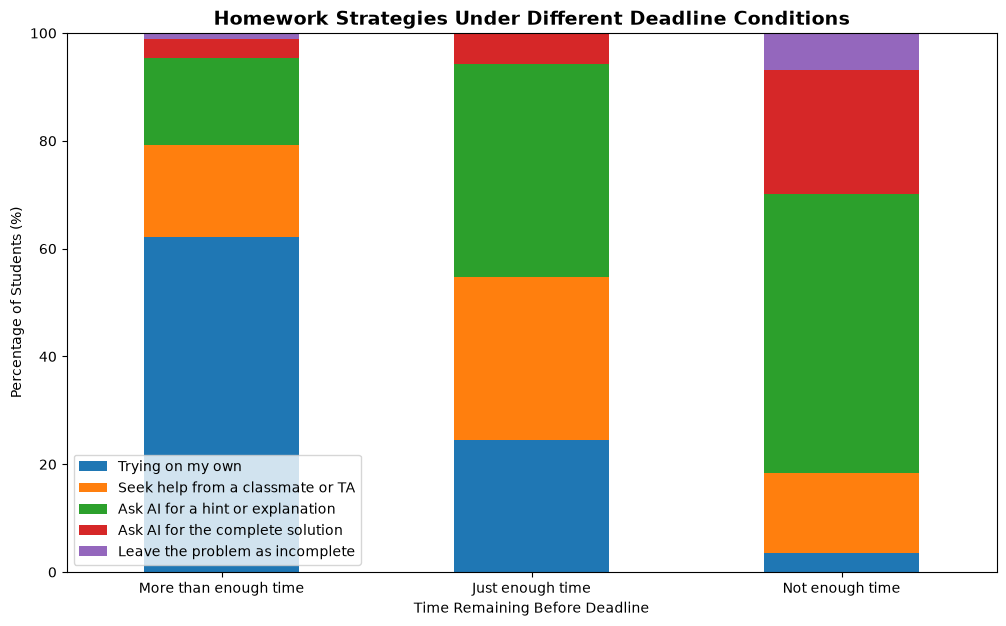

In [15]:
# Create a 100% stacked bar chart to compare homework strategies under different deadline conditions
# Create the stacked bar chart
# stacked=True: Stacks different homework strategies into one bar
# Each bar represents 100% of responses for one deadline situation
percentage_homework.plot.bar(stacked=True, figsize=(12, 7))

# Add title and axis labels
plt.title('Homework Strategies Under Different Deadline Conditions', fontsize=14, fontweight='bold')
plt.xlabel('Time Remaining Before Deadline')
plt.ylabel('Percentage of Students (%)')

# Set the y-axis range from 0% to 100%
plt.ylim(0, 100)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Display the chart
plt.show()

**Interpretation:**

Survey Question:

If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take when you have more than enough time, just enough time, or not enough time before the deadline?

What we suspect:

We think students are more likely to ask AI for hints, explanations, or complete solutions as deadline pressure increases, rather than continuing to solve problems independently.

Our analysis:

We compared students' preferred homework strategies under three different deadline scenarios. We calculated the percentage of students choosing each strategy and displayed the results using a 100% stacked bar chart to show how the distribution of responses changes as available time decreases.

Findings:
When students have more than enough time, 19.5% prefer AI assistance.
When students have just enough time, 45.3% prefer AI assistance.
When students do not have enough time, 74.7% prefer AI assistance.
The percentage choosing to work independently decreases from 62.1% to 3.4% between the first and last scenarios.

Conclusion:

Students are increasingly likely to choose AI assistance as deadline pressure increases. The results suggest an association between having less time to complete homework and a greater preference for AI assistance.

#### Visualization 6: <title>

**What we want to learn:**

**Interpretation:**

#### Visualization 7: <title>

**What we want to learn:**

**Interpretation:**

#### Visualization 8: <title>

**What we want to learn:**

# Question: Do AI deterrents differ by year?

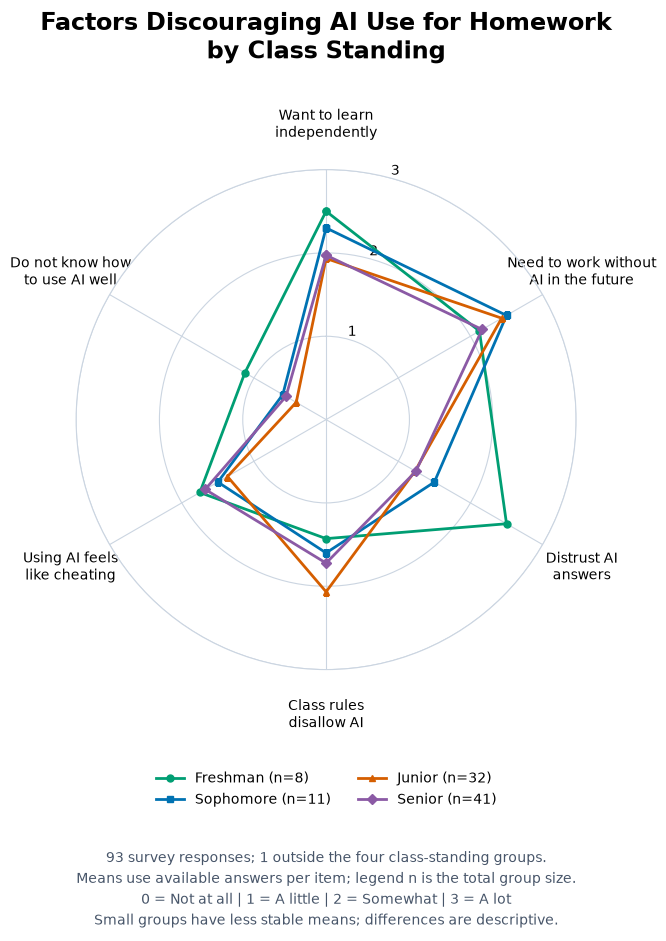

Group mean ratings:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                                          
Freshman                 2.5                 2.12               2.5         1.43                 1.75               1.12
Sophomore                2.3                  2.5               1.5          1.6                  1.5                0.6
Junior                  1.93                 2.43              1.23         2.07                 1.37               0.41
Senior                  1.97                 2.16              1.24         1.72                 1.68               0.56

Valid responses per group and factor:
                learn_myself  future_independence  distrust_answers  class_rules  feels_like_cheating  lack_of_ai_skills
class_standing                                                                                

In [16]:
import numpy as np
import matplotlib.pyplot as plt

order = list(factors)
year_order = ['Freshman', 'Sophomore', 'Junior', 'Senior']
# Use row positions because clean_factors is indexed by original Excel row.
class_standing = pd.Series(
    data['What is your current class standing?'].astype('string').str.strip().to_numpy(),
    index=clean_factors.index, name='class_standing',
)
year_data = clean_factors[order].join(class_standing)
year_data = year_data[year_data['class_standing'].isin(year_order)]
year_means = year_data.groupby('class_standing')[order].mean().reindex(year_order)
year_counts = year_data.groupby('class_standing')[order].count().reindex(year_order)
year_sizes = year_data.groupby('class_standing').size().reindex(year_order, fill_value=0)
label_text = [
    'Want to learn\nindependently', 'Need to work without\nAI in the future',
    'Distrust AI\nanswers', 'Class rules\ndisallow AI',
    'Using AI feels\nlike cheating', 'Do not know how\nto use AI well',
]
angles = np.linspace(0, 2 * np.pi, len(order), endpoint=False)
closed_angles = np.r_[angles, angles[0]]
fig, ax = plt.subplots(figsize=(11, 10), subplot_kw={'projection': 'polar'})
fig.subplots_adjust(left=0.20, right=0.80, top=0.80, bottom=0.30)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_ylim(0, 3)
ax.set_yticks([1, 2, 3])
ax.set_rlabel_position(15)
ax.set_xticks(angles)
ax.set_xticklabels(label_text, fontsize=10)
ax.tick_params(axis='x', pad=22)
ax.grid(color='#cbd5e1', linewidth=0.8)
ax.spines['polar'].set_color('#cbd5e1')
colors = ['#009E73', '#0072B2', '#D55E00', '#8B5AA5']
markers = ['o', 's', '^', 'D']
for year, color, marker in zip(year_order, colors, markers):
    values = year_means.loc[year].astype(float).to_numpy()
    ax.plot(closed_angles, np.r_[values, values[0]], color=color,
            marker=marker, linewidth=2, markersize=5,
            label=f'{year} (n={year_sizes[year]})')
fig.suptitle('Factors Discouraging AI Use for Homework\nby Class Standing',
             fontsize=17, fontweight='bold', y=0.96)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center',
           bbox_to_anchor=(0.5, 0.15), ncol=2, frameon=False)
excluded_year_n = len(data) - len(year_data)
fig.text(0.5, 0.045,
         f'{len(data)} survey responses; {excluded_year_n} outside the four class-standing groups.\n'
         'Means use available answers per item; legend n is the total group size.\n'
         '0 = Not at all | 1 = A little | 2 = Somewhat | 3 = A lot\n'
         'Small groups have less stable means; differences are descriptive.',
         ha='center', fontsize=10, color='#475569', linespacing=1.5)
radar_path = output_dir / 'deterrents_radar.png'
fig.savefig(radar_path, dpi=200, facecolor='white')
plt.show()
plt.close(fig)
print('Group mean ratings:')
print(year_means.round(2).to_string())
print('\nValid responses per group and factor:')
print(year_counts.to_string())
print('\nSaved:', radar_path.name)


**What we want to learn:** How do the six deterrents differ across years?

Each color and marker represents a year. Lines show mean scores on the same 0–3 scale. The legend gives group sizes, and the output gives valid counts per item. The chart excludes one concurrent student whose year is unclear.

**Interpretation:** Future independence had the highest mean for sophomores (2.50), juniors (2.43), and seniors (2.16). For freshmen, independent learning and distrust of AI tied at 2.50. Difficulty using AI had the lowest mean in every group.

Freshman (n=8) and sophomore (n=11) groups are small. The chart describes differences; year-group significance has not been tested.


### II. Formulating and Testing Hypotheses

*At least 3 hypotheses. At least one correlation analysis and one chi-squared test.*

#### Hypothesis 1: <statement>

**Test and justification:**

chi squared test with the mosaic plot in visualization #4

**Result and conclusion:**

#### Hypothesis 2: <statement>

**Test and justification:**

**Result and conclusion:**

### Hypothesis 3: Learning-related ratings are higher than trust/skill ratings

**Scores:**

- Learning score = average of independent learning and future independence.
- Trust/skill score = average of distrust and difficulty using AI.
- Difference = learning score − trust/skill score.

**Test and justification:** Use complete answers to all four items. Scores are paired within each respondent. Run a two-sided Wilcoxon signed-rank test at α = 0.05, using an asymptotic calculation with tie and continuity corrections and excluding zero differences from ranking. A location-shift interpretation requires approximately symmetric differences.

An exact two-sided sign test checks whether positive and negative differences are equally likely, without requiring symmetry. Both tests assume independent respondents. These custom scores and tests are exploratory.


**Result and conclusion:**

In [17]:
from scipy import stats
import json

required = ['learn_myself', 'future_independence', 'distrust_answers', 'lack_of_ai_skills']
paired = clean_factors[required].dropna().astype(float).copy()
paired['learning_score'] = paired[['learn_myself', 'future_independence']].mean(axis=1)
paired['trust_skill_score'] = paired[['distrust_answers', 'lack_of_ai_skills']].mean(axis=1)
paired['difference'] = paired['learning_score'] - paired['trust_skill_score']
difference = paired['difference'].to_numpy()
n_positive = int((difference > 0).sum())
n_negative = int((difference < 0).sum())
n_zero = int((difference == 0).sum())
n_nonzero = n_positive + n_negative
if n_nonzero == 0:
    raise ValueError('All paired differences are zero; no signed-rank or sign test is informative.')
wilcoxon_result = stats.wilcoxon(
    difference, alternative='two-sided', zero_method='wilcox',
    method='asymptotic', correction=True,
)
sign_result = stats.binomtest(n_positive, n_nonzero, p=0.5, alternative='two-sided')
nonzero = difference[difference != 0]
ranks = stats.rankdata(np.abs(nonzero))
w_plus = float(ranks[nonzero > 0].sum())
w_minus = float(ranks[nonzero < 0].sum())
rank_biserial = (w_plus - w_minus) / (w_plus + w_minus)
test_results = {
    'alpha': 0.05, 'alternative': 'two-sided',
    'complete_pairs': len(paired), 'excluded_incomplete_responses': len(data) - len(paired),
    'positive_differences': n_positive, 'negative_differences': n_negative,
    'zero_differences': n_zero, 'nonzero_pairs': n_nonzero,
    'learning_score_mean': float(paired['learning_score'].mean()),
    'trust_skill_score_mean': float(paired['trust_skill_score'].mean()),
    'mean_paired_difference': float(np.mean(difference)),
    'median_paired_difference': float(np.median(difference)),
    'difference_q1': float(np.quantile(difference, 0.25)),
    'difference_q3': float(np.quantile(difference, 0.75)),
    'wilcoxon_statistic': float(wilcoxon_result.statistic),
    'wilcoxon_p_value': float(wilcoxon_result.pvalue),
    'wilcoxon_method': 'tie-corrected asymptotic; continuity correction; zero_method=wilcox',
    'matched_pairs_rank_biserial': rank_biserial,
    'exact_sign_test_p_value': float(sign_result.pvalue),
}
print(json.dumps(test_results, indent=2))
print('\nObserved paired-difference distribution:')
print(paired['difference'].value_counts().sort_index().to_string())
paired.to_csv(output_dir / 'deterrents_paired_scores.csv')
(output_dir / 'deterrents_test_results.json').write_text(json.dumps(test_results, indent=2) + '\n')


{
  "alpha": 0.05,
  "alternative": "two-sided",
  "complete_pairs": 83,
  "excluded_incomplete_responses": 10,
  "positive_differences": 60,
  "negative_differences": 2,
  "zero_differences": 21,
  "nonzero_pairs": 62,
  "learning_score_mean": 2.1566265060240966,
  "trust_skill_score_mean": 0.9939759036144579,
  "mean_paired_difference": 1.1626506024096386,
  "median_paired_difference": 1.5,
  "difference_q1": 0.0,
  "difference_q3": 2.0,
  "wilcoxon_statistic": 31.5,
  "wilcoxon_p_value": 2.680960554745181e-11,
  "wilcoxon_method": "tie-corrected asymptotic; continuity correction; zero_method=wilcox",
  "matched_pairs_rank_biserial": 0.967741935483871,
  "exact_sign_test_p_value": 8.474124180146703e-16
}

Observed paired-difference distribution:
difference
-1.5     1
-0.5     1
 0.0    21
 0.5     5
 1.0    12
 1.5    18
 2.0    14
 2.5     8
 3.0     3


716

**Result and conclusion:** For 83 complete pairs, learning scores averaged 2.16 and trust/skill scores averaged 0.99. The mean paired difference was 1.16. Wilcoxon W = 31.5, p = 2.68e-11; sign-test p = 8.47e-16. The results support higher learning-related ratings. Ten incomplete responses were excluded.


#### Hypothesis 4: Class-rule and cheating-related deterrents are associated

**H0:** The two deterrents are independent.

**H1:** The two deterrents are associated.

**Grouping:** Lower = Not at all / A little. Higher = Somewhat / A lot. This split separates weaker and stronger barriers but loses detail.

**Test and justification:** Use a 2 × 2 chi-squared independence test with Yates correction at α = 0.05. Include respondents who answered both items. Each respondent enters one cell, and all expected counts must be at least 5. Responses are assumed independent.

The class-rule item measures a reported barrier, not the actual course policy.


In [18]:
from scipy import stats

chi_answers = clean_factors[['class_rules', 'feels_like_cheating']].dropna()
chi_group_map = {0: 'Lower deterrence', 1: 'Lower deterrence',
                 2: 'Higher deterrence', 3: 'Higher deterrence'}
chi_groups = chi_answers.apply(lambda column: column.map(chi_group_map))
chi_levels = ['Lower deterrence', 'Higher deterrence']
chi_observed = pd.crosstab(
    chi_groups['class_rules'], chi_groups['feels_like_cheating'],
).reindex(index=chi_levels, columns=chi_levels, fill_value=0)
chi_observed.index.name = 'Class-rule deterrence'
chi_observed.columns.name = 'Cheating-related deterrence'
if (chi_observed.sum(axis=0) == 0).any() or (chi_observed.sum(axis=1) == 0).any():
    raise ValueError('Both deterrence groups must be represented for each item.')
chi_statistic, chi_p_value, chi_dof, chi_expected_array = stats.chi2_contingency(
    chi_observed, correction=True,
)
chi_expected = pd.DataFrame(
    chi_expected_array, index=chi_observed.index, columns=chi_observed.columns,
)
if (chi_expected_array < 5).any():
    raise ValueError('Expected cell counts are below 5; reassess the chi-squared method.')
chi_higher_percent = 100 * chi_observed['Higher deterrence'] / chi_observed.sum(axis=1)
print(f'Complete responses: {len(chi_answers)}; excluded: {len(data) - len(chi_answers)}')
print('Observed counts (rows = class rules; columns = cheating):')
print(chi_observed.to_string())
print('\nExpected counts:')
print(chi_expected.round(2).to_string())
print(f'\nPearson chi-squared with Yates correction: chi2({chi_dof}) = '
      f'{chi_statistic:.4f}, p = {chi_p_value:.6g}')
print('\nHigher cheating-related deterrence within each class-rule group (%):')
print(chi_higher_percent.round(1).to_string())


Complete responses: 84; excluded: 9
Observed counts (rows = class rules; columns = cheating):
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                           22                  7
Higher deterrence                          19                 36

Expected counts:
Cheating-related deterrence  Lower deterrence  Higher deterrence
Class-rule deterrence                                           
Lower deterrence                        14.15              14.85
Higher deterrence                       26.85              28.15

Pearson chi-squared with Yates correction: chi2(1) = 11.3720, p = 0.000745598

Higher cheating-related deterrence within each class-rule group (%):
Class-rule deterrence
Lower deterrence     24.1
Higher deterrence    65.5


**Result and conclusion:** Among 84 complete responses, higher cheating-related deterrence was reported by 65.5% of the higher class-rule group and 24.1% of the lower group. χ²(1) = 11.37, p = 0.000746, with Yates correction. All expected counts exceeded 5. Reject H0 at α = 0.05.

The two reported barriers are associated in this sample. This exploratory analysis does not establish causation.


## Overall Conclusion

*Summarize findings and relate them back to the original questions.*

## Group Contributions

| Member | Contribution |
|---|---|
| jcarb044 | |
| jprad022 | |
| jyu356 | |
| kaung006 | |
| slian088 | |